In [1]:
from astropy.io import fits
from astropy.wcs import WCS
import astropy
from astropy.coordinates import SkyCoord 
from astropy.wcs.utils import skycoord_to_pixel
from astropy.wcs.utils import pixel_to_skycoord
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
plt.rcParams.update({'font.size': 12})
plt.style.use('seaborn-dark-palette')

from os import listdir
from os.path import isfile, join
from datetime import datetime
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore', category=UserWarning, append=True)
warnings.filterwarnings("ignore", category=astropy.wcs.FITSFixedWarning)

import ta_func_2022 as ta

In [2]:
#get all of the files 
img_files = [f for f in listdir('.') if isfile(join('.', f)) and 'fits' in f and 'AST325' in f]

file_times = []
for f in img_files:
    if f == 'AST325-326-SN-20150930.5694.fits':
        continue
    header = fits.open(f)[0].header
    dt = datetime.fromisoformat(header["DATE-OBS"])
    file_times.append(dt)

#sort files by the same way
file_times, img_files = zip(*sorted(zip(file_times, img_files)))

img_files = np.array(img_files)
file_times = np.array(file_times)

file_times_numeric = np.array([f.timestamp() for f in file_times])


In [3]:
#Repeating the code from above
# boxsize = 50

# sub_im = np.empty((2*boxsize+1,2*boxsize+1))

# #Create an aperture and annulus model
# aperture = ta.get_aperture(sub_im.shape, 12)
# annulus = ta.get_annulus(sub_im.shape, 20, 40)

# data, header  = ta.read_file(img_files[0])
# w = WCS(header)
# super_nova = pixel_to_skycoord(data.shape[0]//2,data.shape[1]//2, w)

# stars = [*ta.ref_stars,super_nova]

# fluxes = np.empty((len(stars),len(img_files)))
# fluxes_err = np.empty_like(fluxes)



# for i, f in enumerate(img_files):
#     #print(f)
#     data, header  = ta.read_file(f)
#     w = WCS(header)
    
#     for j, star in enumerate(stars):
        
        
#         ref_pos = skycoord_to_pixel(star, w)
#         ref_x, ref_y = ref_pos
#         ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)
#         sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
#                     ref_x_int-boxsize: ref_x_int+boxsize+1]
#         # if f == 'AST325-326-SN-20150930.5694.fits':
#         #         plt.imshow(sub_im)
#         #         plt.show()
#         try:
#             sub_im = ta.center_image(data, sub_im, ref_pos)
#             fluxes[j,i], fluxes_err[j,i]  = ta.get_flux(sub_im, aperture, annulus, gain = 4)
#         except:
#             print('skip')
#         #Get the flux for each of the reference stars 
        
# np.save("fluxes", fluxes)
# np.save("fluxes_err", fluxes_err)

fluxes = np.load("fluxes.npy")
fluxes_err = np.load("fluxes_err.npy")

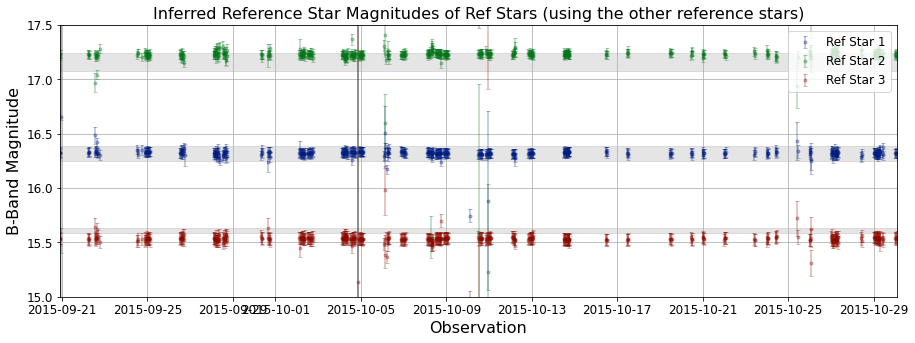

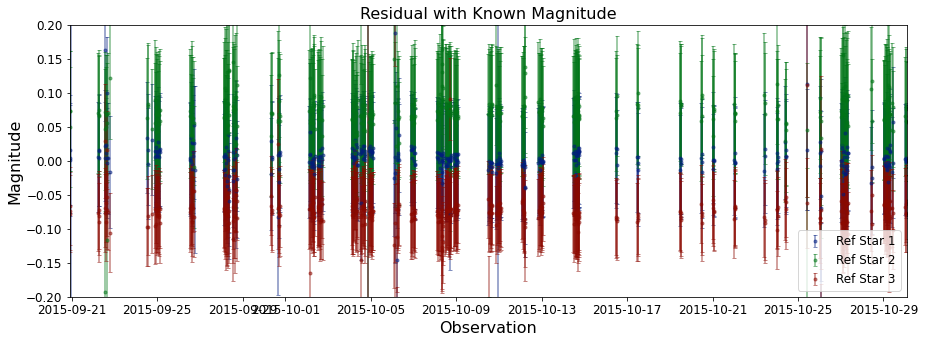

In [4]:
ref_lightcurves, ref_lightcurves_err = ta.do_stuff(fluxes, fluxes_err, xvals = file_times)

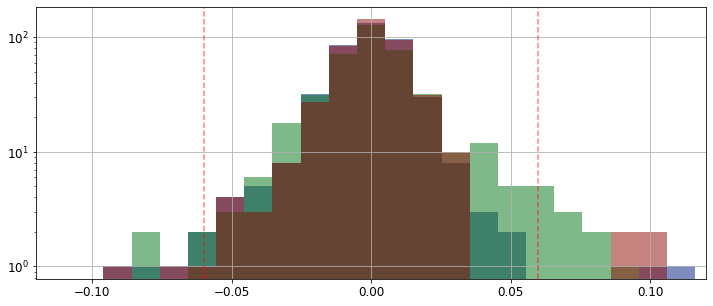

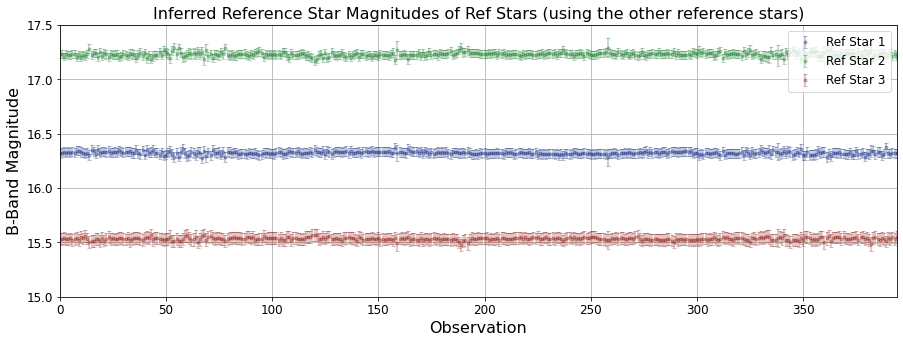

In [5]:
ACCEPTED_DATA_RANGE = 0.06


plt.figure(figsize=(12,5))
for i in range(ref_lightcurves.shape[0]):
    plt.hist(ref_lightcurves[i] - np.median(ref_lightcurves[i]), bins = np.linspace(-0.5,0.5,100), alpha = 0.5)
plt.axvline(x = -ACCEPTED_DATA_RANGE, linestyle = '--', color = 'r', alpha = 0.5)
plt.axvline(x = ACCEPTED_DATA_RANGE, linestyle = '--', color = 'r', alpha = 0.5)
plt.yscale('log')
plt.xlim(-2*ACCEPTED_DATA_RANGE, 2*ACCEPTED_DATA_RANGE)
plt.grid()
plt.show()

_filter = np.ones(ref_lightcurves.shape[1]) == 1
for i in range(ref_lightcurves.shape[0]):
    _filter = _filter & (np.abs(ref_lightcurves[i] - np.median(ref_lightcurves[i])) < ACCEPTED_DATA_RANGE)

plt.figure(figsize = (15,5))
for i in range(len(ref_lightcurves)):
    curve, err = ref_lightcurves[i][_filter], ref_lightcurves_err[i][_filter]
    xvals = np.arange(curve.size)
    plt.errorbar(xvals, curve, yerr = err, fmt = '.', label = f'Ref Star {i+1}', capsize = 2, alpha = 0.3)
plt.xlabel("Observation", size = 16)
plt.ylabel("B-Band Magnitude", size = 16)
plt.title("Inferred Reference Star Magnitudes of Ref Stars (using the other reference stars)", size = 16)
plt.ylim(15, 17.5)
plt.xlim(np.min(xvals), np.max(xvals))
plt.legend(loc = 1)
plt.grid(which = 'major', alpha = 1)
plt.grid(which = 'minor', alpha = 0.3)
plt.show()

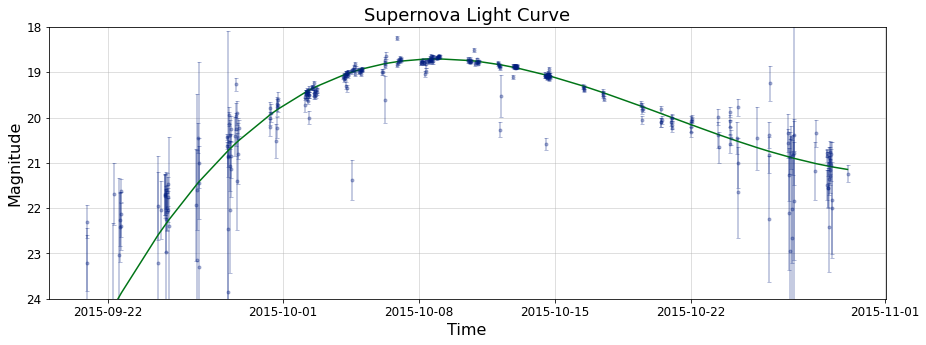

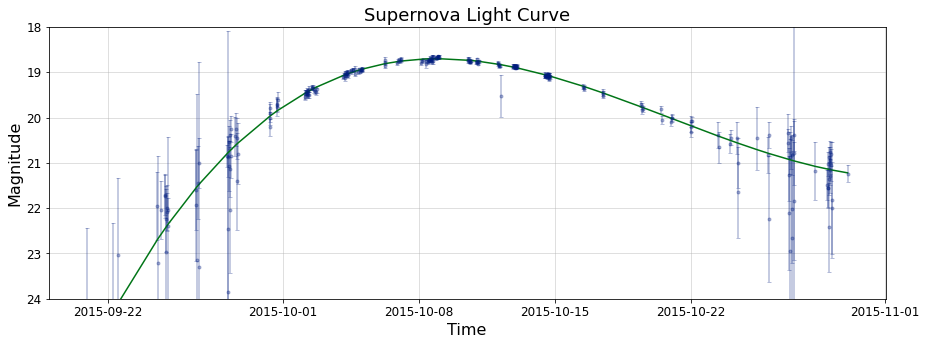

In [6]:
from uncertainties import ufloat
from uncertainties import unumpy
SN_flux = fluxes[-1,:]
SN_flux_err = fluxes_err[-1,:]

ref_mags = [16.32, 17.16, 15.61]
ref_mag_err = [0.07, 0.08, 0.02]
ref_mags_u = [ufloat(ref_mags[i], ref_mag_err[i]) for i in range(len(ref_mags))]
SN_lightcurves = np.empty((len(ref_mags),SN_flux.shape[0]))
SN_lightcurves_err = np.empty_like(SN_lightcurves)

SN_flux_u = unumpy.uarray(SN_flux, SN_flux_err)
for j in range(len(ref_mags)):
    cur_star_flux = unumpy.uarray(fluxes[j,:], fluxes_err[j,:])

    ratio = cur_star_flux/SN_flux_u
    ratio[ratio<0] = 1e-10
    ref_curve_u = 2.512*unumpy.log10(ratio) + ref_mags_u[j]
    SN_lightcurves[j,:] += unumpy.nominal_values(ref_curve_u)
    SN_lightcurves_err[j,:] = unumpy.std_devs(ref_curve_u)

SN_lightcurve = np.mean(SN_lightcurves, axis = 0)
SN_lightcurve_err = np.sqrt(np.sum(SN_lightcurves_err**2, axis = 0))/SN_lightcurves_err.shape[0]

_filter = _filter&(SN_lightcurve > 18)&(SN_lightcurve < 25)

coefs, cov = np.polyfit(file_times_numeric[_filter],SN_lightcurve[_filter],3, w = 1/SN_lightcurve_err[_filter]**2, cov = True)

p = np.poly1d(coefs)
plt.figure(figsize = (15,5))
plt.errorbar(file_times[_filter], SN_lightcurve[_filter], yerr = SN_lightcurve_err[_filter], fmt = '.', capsize = 2, alpha = 0.3)
plt.plot(file_times[_filter], p(file_times_numeric[_filter]))
plt.ylim(24,18)
plt.ylabel('Magnitude', size = 16)
plt.xlabel('Time', size = 16)
plt.title("Supernova Light Curve", size = 18)
plt.grid(which='both', alpha = 0.5)
plt.show()

#Filter out any stragglers that are more than two sigma from fit
_filter = _filter & (np.abs(SN_lightcurve- p(file_times_numeric)) < 1.5*SN_lightcurve_err)

coefs, cov = np.polyfit(file_times_numeric[_filter],SN_lightcurve[_filter],3, w = 1/SN_lightcurve_err[_filter]**2, cov = True)

p = np.poly1d(coefs)
plt.figure(figsize = (15,5))
plt.errorbar(file_times[_filter], SN_lightcurve[_filter], yerr = SN_lightcurve_err[_filter], fmt = '.', capsize = 2, alpha = 0.3)
plt.plot(file_times[_filter], p(file_times_numeric[_filter]))
plt.ylim(24,18)
plt.ylabel('Magnitude', size = 16)
plt.xlabel('Time', size = 16)
plt.title("Supernova Light Curve", size = 18)
plt.grid(which='both', alpha = 0.5)
plt.show()


**Let's assume some exponential decay profile for our lightcurve, driven by the radioactive decay of a single element**\
**L(t) = L0 * exp(-t / T_half)**


In [7]:
def decay_function(t, L0, T_half):
    return L0 * np.exp(-t / T_half)

In [8]:
from scipy.optimize import curve_fit


In [9]:
L0_guess=3.5e-8
T_half_guess=750000

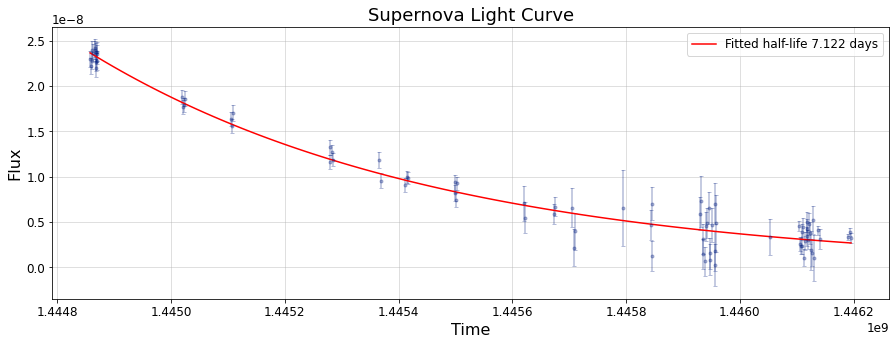

In [10]:

lc = unumpy.uarray(SN_lightcurve[_filter], SN_lightcurve_err[_filter])
lc_flux = 10**(-0.4*lc)
ydata =  unumpy.nominal_values(lc_flux)
yerr = unumpy.std_devs(lc_flux)

xdata = file_times_numeric[_filter]
decay_filter = (xdata > xdata[xdata.size//2])

ydata = ydata[decay_filter]
yerr = yerr[decay_filter]
xdata = xdata[decay_filter]
times = xdata-xdata[0]


initial_guess = (L0_guess, T_half_guess)  # Provide initial guesses
params, covariance = curve_fit(decay_function, times, ydata, p0=initial_guess)

fitted_L0, fitted_T_half = params

t_fit = np.linspace(min(times), max(times), 100)

# Calculate the fitted luminosity values using the fitted parameters
fitted_luminosity = decay_function(t_fit, fitted_L0, fitted_T_half)



plt.figure(figsize = (15,5))
plt.errorbar(xdata, ydata, yerr = yerr, fmt = '.', capsize = 2, alpha = 0.3)
plt.plot(t_fit+xdata[0], fitted_luminosity, label=f"Fitted half-life {round(fitted_T_half/3600/24,3)} days", color="red")

#plt.plot(xdata, p(xdata))
# plt.ylim(24,18)
plt.ylabel('Flux', size = 16)
plt.xlabel('Time', size = 16)
plt.title("Supernova Light Curve", size = 18)
plt.grid(which='both', alpha = 0.5)
plt.legend()
plt.show()